## Análisis de modelos

## Red neuronal

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)

import keras
from keras import layers
from tensorflow.keras import regularizers, callbacks
import joblib
import mlflow

In [95]:
df = pd.read_csv("../data/raw/billboard_processed.csv")

df.head()

,performer,spotify_genre,spotify_track_duration_ms,spotify_track_explicit,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature,acoustic_mood_cluster,top30
0,The Weeknd,"['canadian contemporary r&b', 'canadian pop', ...",201573.0,False,0.513,1.0,-4.075,1.0,0.0629,0.000209,171.017,4.0,intense_aggressive_drive,1
1,LMFAO Featuring Lauren Bennett & GoonRock,"['dance pop', 'pop', 'pop rap']",262173.0,False,0.750,5.0,-4.210,0.0,0.1420,0.000000,129.993,4.0,intense_aggressive_drive,1
2,Adele,"['british soul', 'pop', 'uk pop']",228293.0,False,0.729,8.0,-5.119,1.0,0.0294,0.000000,104.945,4.0,balanced_acoustic_pop,1
3,Post Malone,"['dfw rap', 'melodic rap', 'rap']",215280.0,False,0.695,0.0,-3.497,1.0,0.0395,0.002440,120.042,4.0,balanced_acoustic_pop,1
4,Los Del Rio,"['deep norteno', 'duranguense', 'norteno', 'no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop,1


## Decimos a MLflow dónde guardar:

In [ ]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")   
mlflow.set_experiment("experimento_musica")

## Analizar variable "top30":

top30
0    18112
1    12659
Name: count, dtype: int64

Porcentajes:
top30
0    58.860616
1    41.139384
Name: proportion, dtype: float64


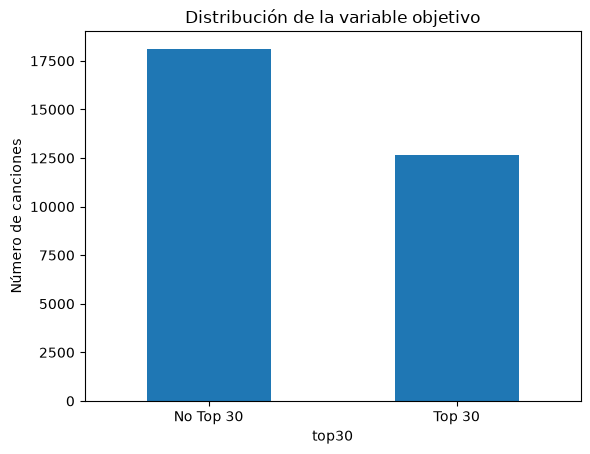

In [96]:
print(df["top30"].value_counts())
print("\nPorcentajes:")
print(df["top30"].value_counts(normalize=True) * 100)

df["top30"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.xticks([0, 1], ["No Top 30", "Top 30"])
plt.ylabel("Número de canciones")
plt.title("Distribución de la variable objetivo")
plt.show()

## Separamos train y test:

In [97]:
X = df.drop(columns=["top30"])
y = df["top30"]

X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.10, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.10, random_state=42, stratify=y_resto)


print(X_train.shape,X_val.shape, X_test.shape)
print('En train:', round(y_train.mean() * 100, 2), "%", 'En validación: ',round(y_val.mean()*100,2),"%" , '  en test:', round(y_test.mean() * 100, 2), "%")

(24923, 13) (2770, 13) (3078, 13)
En train: 41.14 % En validación:  41.16 %   en test: 41.13 %


In [98]:
print("Columnas de X:")
print(X_train.columns.tolist())

print("\nDimensiones:")
print(X_train.shape)

print("\nColumnas con nulos:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Columnas de X:
['performer', 'spotify_genre', 'spotify_track_duration_ms', 'spotify_track_explicit', 'danceability', 'key', 'loudness', 'mode', 'speechiness', 'instrumentalness', 'tempo', 'time_signature', 'acoustic_mood_cluster']

Dimensiones:
(24923, 13)

Columnas con nulos:
spotify_track_duration_ms    2976
spotify_track_explicit       2976
danceability                 3025
key                          3025
loudness                     3025
mode                         3025
speechiness                  3025
instrumentalness             3025
tempo                        3025
time_signature               3025
dtype: int64


## Aplicamos el análisis en X_train

In [99]:
variables_media = ["danceability", "speechiness", "instrumentalness", "tempo"]
variables_mediana = ["loudness"]
variables_moda = ["key", "mode", "time_signature"]

globales_mediana = ["spotify_track_duration_ms"]
globales_moda = ["spotify_track_explicit"]

cluster_col = "acoustic_mood_cluster"
columnas_cluster = variables_media + variables_mediana + variables_moda
columnas_globales = globales_mediana + globales_moda
columnas = columnas_cluster + columnas_globales

print("Nulos TRAIN antes:")
print(X_train[columnas].isna().sum())

stats_cluster = {}   # {columna: Serie indexada por cluster}
stats_global = {}    # {columna: valor global}

for col in variables_media:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].mean()
    stats_global[col] = X_train[col].mean()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_mediana:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].median()
    stats_global[col] = X_train[col].median()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_moda:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].agg(
        lambda x: x.mode().iloc[0] if not x.mode().empty else float("nan")
    )
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_mediana:
    stats_global[col] = X_train[col].median()
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_moda:
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")
    X_train[col] = X_train[col].fillna(stats_global[col])

print("\nNulos TRAIN después:")
print(X_train[columnas].isna().sum())

print("\nEstadísticas globales guardadas (train):")
print(stats_global)

Nulos TRAIN antes:
danceability                 3025
speechiness                  3025
instrumentalness             3025
tempo                        3025
loudness                     3025
key                          3025
mode                         3025
time_signature               3025
spotify_track_duration_ms    2976
spotify_track_explicit       2976
dtype: int64

Nulos TRAIN después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64

Estadísticas globales guardadas (train):
{'danceability': np.float64(0.6020063932779248), 'speechiness': np.float64(0.08950473102566445), 'instrumentalness': np.float64(0.032657926696501964), 'tempo': np.float64(121.06935149328706), 'loudness': -8.13, 'key': np.float64(0.0), 'mode'

C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_20552\3074567703.py:53: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train[col] = X_train[col].fillna(stats_global[col])


## Rellenamos nulos en X_val 

In [100]:
print("Nulos VAL antes:")
print(X_val[columnas].isna().sum())

# Con cluster
for col in columnas_cluster:
    valor_cluster = X_val[cluster_col].map(stats_cluster[col])
    X_val[col] = X_val[col].fillna(valor_cluster)
    X_val[col] = X_val[col].fillna(stats_global[col])

# Solo global
for col in columnas_globales:
    X_val[col] = X_val[col].fillna(stats_global[col])

print("\nNulos VAL después:")
print(X_val[columnas].isna().sum())

Nulos VAL antes:
danceability                 319
speechiness                  319
instrumentalness             319
tempo                        319
loudness                     319
key                          319
mode                         319
time_signature               319
spotify_track_duration_ms    315
spotify_track_explicit       315
dtype: int64

Nulos VAL después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_20552\3902017654.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_val[col] = X_val[col].fillna(stats_global[col])


## Rellenamos nulos en X_test

In [101]:
print("Nulos TEST antes:")
print(X_test[columnas].isna().sum())

# Con cluster
for col in columnas_cluster:
    valor_cluster = X_test[cluster_col].map(stats_cluster[col])
    X_test[col] = X_test[col].fillna(valor_cluster)
    X_test[col] = X_test[col].fillna(stats_global[col])

# Solo global
for col in columnas_globales:
    X_test[col] = X_test[col].fillna(stats_global[col])

print("\nNulos TEST después:")
print(X_test[columnas].isna().sum())

Nulos TEST antes:
danceability                 365
speechiness                  365
instrumentalness             365
tempo                        365
loudness                     365
key                          365
mode                         365
time_signature               365
spotify_track_duration_ms    359
spotify_track_explicit       359
dtype: int64

Nulos TEST después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_20552\387698589.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test[col] = X_test[col].fillna(stats_global[col])


In [ ]:
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())

Train: 0
Validation: 0


## Realizamos OneHotEncoder
- A las variables de tipo texto las convertimos en números ya que la regresión logística se hace con números.
- Tras realizar la ejeccución nos dimos cuenta que siguiendo este hilo daba sobreajuste.

In [103]:
texto = ["performer", "spotify_genre", "acoustic_mood_cluster", "spotify_track_explicit"]
encoder = OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)
encoder.fit(X_train[texto])  
nombres = encoder.get_feature_names_out(texto)
print(nombres)

cat_train = pd.DataFrame(encoder.transform(X_train[texto]), columns=nombres, index=X_train.index)
cat_val = pd.DataFrame(encoder.transform(X_val[texto]), columns=nombres, index=X_val.index)
cat_test = pd.DataFrame(encoder.transform(X_test[texto]), columns=nombres, index=X_test.index)

X_train = pd.concat([X_train.drop(columns=texto), cat_train], axis=1)
X_val =  pd.concat([X_val.drop(columns=texto), cat_val], axis=1)
X_test =  pd.concat([X_test.drop(columns=texto), cat_test], axis=1)
print('Columnas del modelo:', X_train.shape[1])
X_train.head()

print("Nulos después del OneHotEncoder:")
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())


['performer_"Little" Jimmy Dickens' 'performer_"Pookie" Hudson'
 'performer_"Weird Al" Yankovic' ...
 'acoustic_mood_cluster_intense_aggressive_drive'
 'acoustic_mood_cluster_moody_melancholic' 'spotify_track_explicit_True']


c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Columnas del modelo: 11001
Nulos después del OneHotEncoder:
Train: 0
Validation: 0


## Ajustamos la red neuronal

- early_stopping -> Hemos decidido que si el modelo no mejora ("val_loss") se detenga el proceso, la paciencia que hemos elegido es de 15 epócas.
- reduce_lr -> Este mecanismo reduce la tasa de aprendizaje cuando el modelo deja de mejorar en validación, pero en este caso la paciencia es de 5 epócas.
- layers.Dense(1, activation="sigmoid") -> Hemos elegido una sigmoide ya que nos devuelve un valor entre 0 y 1 de tal forma que podemos sacar una probabilidad.


In [ ]:
keras.utils.set_random_seed(42)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    min_delta=0.001,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.000001,
    verbose=1
)

mlflow.end_run() 
with mlflow.start_run(run_name="modelo_red_neuronal"): 

    mlflow.log_params({"capas": "16-8-1", "lr": 0.0001, "batch_size": 32})  

    model_base = keras.Sequential([
        keras.Input(shape=(11001,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(8, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

    model_base.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0001),
        loss="binary_crossentropy"
    )

    history_base = model_base.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=200,
        batch_size=32,
        callbacks=[early_stopping, reduce_lr],
        verbose=1
    )

    # MLflow: métricas y modelo
    mlflow.log_metric("train_loss", min(history_base.history["loss"]))
    mlflow.log_metric("val_loss", min(history_base.history["val_loss"]))
    mlflow.log_metric("epocas", len(history_base.history["loss"]))
    mlflow.keras.log_model(model_base, name="modelo_red_neuronal")

Epoch 1/200
779/779 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 56.5722 - val_loss: 1.5214 - learning_rate: 1.0000e-04
Epoch 2/200
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.2457 - val_loss: 2.5376 - learning_rate: 1.0000e-04
Epoch 3/200
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.4559 - val_loss: 0.6921 - learning_rate: 1.0000e-04
Epoch 4/200
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.2404 - val_loss: 2.4360 - learning_rate: 1.0000e-04
Epoch 5/200
779/779 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 1.2936 - val_loss: 0.7087 - learning_rate: 1.0000e-04
Epoch 6/200
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.2751 - val_loss: 2.3737 - learning_rate: 1.0000e-04
Epoch 7/200
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.3983 - val_loss: 3.0751 - learning_rate: 1.0000e-04
Epoch 8/200
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.2413 - val_loss: 0.6591 - learning_rate: 1.0000e-04
Epoch 9/200
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.1780 - val_loss:

## Analizamos los resultados que nos devuelve train
- Miramos el porcentaje de aciertos.
- Sacamos la mátriz de confusión.
- Sacamos diferentes metricas para el análisis final.

In [117]:
probabilidades = model_base.predict(X_train).flatten()



predicciones = (probabilidades >= 0.5).astype(int)

aciertos = (predicciones == y_train).sum()
total = len(y_train)

print(f"Aciertos: {aciertos}/{total}")
print(f"Porcentaje de acierto: {aciertos / total * 100:.2f}%")



779/779 ━━━━━━━━━━━━━━━━━━━━ 1s 825us/step
Aciertos: 16838/24923
Porcentaje de acierto: 67.56%


779/779 ━━━━━━━━━━━━━━━━━━━━ 1s 721us/step


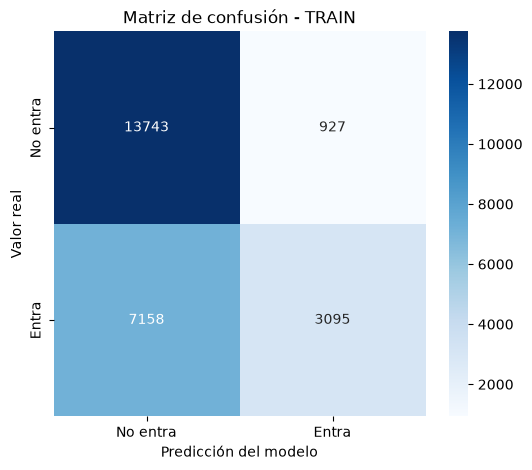

In [118]:
probabilidades = model_base.predict(X_train).flatten()

predicciones = (probabilidades >= 0.5).astype(int)

matriz = confusion_matrix(y_train, predicciones)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No entra", "Entra"],
    yticklabels=["No entra", "Entra"]
)

plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - TRAIN")

plt.show()

In [123]:
print("Accuracy:", accuracy_score(y_train, predicciones))
print("Precision:", precision_score(y_train, predicciones))
print("Recall:", recall_score(y_train, predicciones))
print("F1-score:", f1_score(y_train, predicciones))
print("ROC-AUC:", roc_auc_score(y_train, probabilidades))

Accuracy: 0.6756008506199093
Precision: 0.7695176529090005
Recall: 0.30186286940407686
F1-score: 0.43362521891418565
ROC-AUC: 0.7427281861607532


## Analizamos los resultados que nos devuelve test

In [ ]:
probabilidades = model_base.predict(X_test).flatten()

predicciones = (probabilidades >= 0.5).astype(int)

aciertos = (predicciones == y_test).sum()
total = len(y_test)

print(f"Aciertos: {aciertos}/{total}")
print(f"Porcentaje de acierto: {aciertos / total * 100:.2f}%")




97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Aciertos: 2057/3078
Porcentaje de acierto: 66.83%


97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


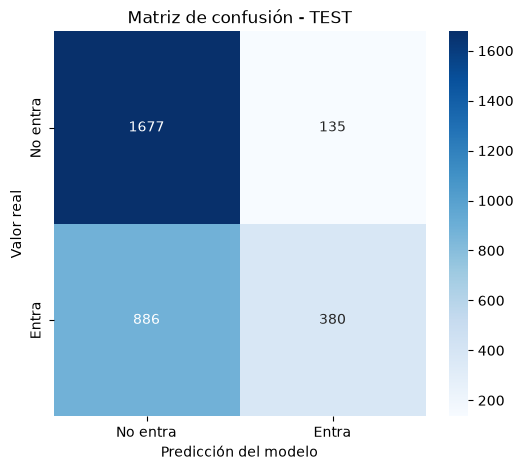

In [ ]:
probabilidades = model_base.predict(X_test).flatten()

predicciones = (probabilidades >= 0.5).astype(int)

matriz = confusion_matrix(y_test, predicciones)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No entra", "Entra"],
    yticklabels=["No entra", "Entra"]
)

plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - TEST")

plt.show()

## Guardar modelo:

In [121]:
joblib.dump(model_base, "../model/RedNeuronal_model.joblib")

print("Modelo guardado correctamente")

Modelo guardado correctamente


## Reflexión final:

Tras entrenar y evaluar la red neuronal, se han obtenido resultados moderados, destacando especialmente su precision de 0.770 y su ROC-AUC de 0.743, aunque presenta un recall relativamente bajo de 0.302 y un F1-score de 0.434.

La precisión es la métrica más destacable de este modelo, ya que indica que aproximadamente el 77 % de las canciones clasificadas como potenciales éxitos realmente alcanzan el Top 30 de Billboard 100. Desde el punto de vista empresarial de la IA, este comportamiento resulta interesante, puesto que permite identificar canciones con una mayor probabilidad de éxito y reducir las falsas recomendaciones. Esto podría ayudar a una discográfica a seleccionar canciones en las que considere más interesante invertir recursos promocionales.

Sin embargo, esta precisión elevada viene acompañada de un recall de 0.302. Esto significa que el modelo solamente consigue identificar aproximadamente el 30,2 % de las canciones que realmente alcanzan el Top 30, dejando sin detectar cerca del 69,8 % de los casos positivos. Por tanto, aunque sus recomendaciones suelen ser acertadas, el modelo pierde muchas canciones que podrían tener potencial comercial.

Por otra parte, el accuracy de 0.676 indica que el modelo clasifica correctamente aproximadamente el 67,6 % de las canciones analizadas. Mientras tanto, el ROC-AUC de 0.743 refleja una capacidad de discriminación moderadamente buena entre las canciones que alcanzan el Top 30 y aquellas que no. El F1-score de 0.434 muestra que todavía existe un desequilibrio importante entre la precisión y el recall.

Una de las ventajas de esta red neuronal es que, gracias a la función de activación Sigmoid en su capa de salida, permite obtener probabilidades estimadas de éxito para cada canción. Esto resulta especialmente útil para el problema planteado, ya que permite valorar el potencial comercial de las canciones sin depender exclusivamente de una clasificación automática entre éxitos y no éxitos.

En conclusión, considero que esta red neuronal presenta un comportamiento interesante cuando se busca identificar canciones con una mayor probabilidad de alcanzar el Top 30, debido a su precisión relativamente elevada. Sin embargo, su bajo recall supone una limitación importante si el objetivo de la discográfica es detectar la mayor cantidad posible de canciones con potencial comercial.

Por tanto, mantendría este modelo como una alternativa a considerar durante la comparación final, aunque estudiaría la modificación del umbral de clasificación y otros ajustes de la red neuronal para intentar mejorar el recall sin reducir excesivamente la precisión.